# Isolation Forest Outlier Evaluation

Minimal notebook that: loads a `Study`, extracts features from `issf_dataset` items (features already combine movement+env+interactions), trains an `IsolationForest` on the train split, evaluates on the test split, and (optionally) runs across a studies directory and saves aggregated results.

Edit `STUDY_ID` or `STUDIES_DIR` below to run on your data.

In [2]:
# Config + imports
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import seaborn as sns
#sns.set(style='whitegrid')

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve
from sklearn.decomposition import PCA

# repo APIs
from movebench import Study
from movebench.trajectories import SET_COL, OUTLIER_COL

# User settings
STUDY_ID = 'Carter_Red_Fox'  # change to a study you have
LAYER_CONFIG = '../configs/layers_all.yaml'
NUM_CANDIDATES = 100
SAMPLE_N = None  # max samples per split (None = all)
RANDOM_SEED = 0
TOP_K_VALUES = (1, 5, 10, 25, 50)
NUM_CANDIDATES = 100
SAMPLER_RANDOM_SEED = 0
STEP_MULTIPLIER = 2.0
STEP_Q = 0.95
GAP_Q = 0.999
BOUNDS_BUFFER_DEG = 0.01
RESULTS_DIR = Path('/data/vision/beery/scratch/shir/results/movebench/prlim_byindividual/isolation_forest/')
FIG_DIR = Path(RESULTS_DIR,'figures')
RESULTS_DIR.mkdir(exist_ok=True, parents=True)
FIG_DIR.mkdir(exist_ok=True, parents=True)


In [3]:
# Load study and create datasets (train/test)
study = Study(STUDY_ID)
print('study dir:', study.study_dir)
train_ds = study.issf_dataset(split="train",
    config=LAYER_CONFIG,
    include_time=False,
    normalize=True,
    num_candidates=NUM_CANDIDATES,
    random_seed=SAMPLER_RANDOM_SEED,
    step_multiplier=STEP_MULTIPLIER,
    step_q=STEP_Q,
    gap_q=GAP_Q,
    bounds_buffer_deg=BOUNDS_BUFFER_DEG
)

test_ds = study.issf_dataset(  split="test",
    config=LAYER_CONFIG,
    include_time=False,
    normalize=True,
    num_candidates=NUM_CANDIDATES,
    random_seed=SAMPLER_RANDOM_SEED,
    step_multiplier=STEP_MULTIPLIER,
    step_q=STEP_Q,
    gap_q=GAP_Q,
    bounds_buffer_deg=BOUNDS_BUFFER_DEG,)
print('train len:', len(train_ds), 'test len:', len(test_ds))


study dir: /archive/vision/beery/movebench/studies_10ind/Carter_Red_Fox
train len: 12989 test len: 8208


In [6]:
# Helper: extract flattened feature vectors and labels from a dataset
import torch
def ds_features_and_labels(ds, study, n_candidates, sample_n=None, random_seed=42):
    n = len(ds)
    if n == 0:
        return np.empty((0,0)), np.empty((0,), dtype=bool), []
    if sample_n is None or sample_n >= n:
        indices = np.arange(n)
    else:
        rng = np.random.default_rng(random_seed)
        indices = rng.choice(n, size=sample_n, replace=False)

    feats = []
    pids = []
    for idx in indices:
        #x, valid, _, _ = ds[int(idx)]  # x shape: (C, P)
        x=ds._movement_features(idx)
        if x is None:
            continue
        if isinstance(x, torch.Tensor):
            x = x.detach().cpu().numpy()
        # if candidates dimension exists, take last candidate (true point)
        if NUM_CANDIDATES > 0:
            vec = x[...,-1]
        else:
            vec = x.reshape(-1)
        feats.append(vec)
        # dataset exposes point_id_start mapping in example notebook; fallback to idx
        pid = int(ds.point_id_start[idx].item())
        pids.append(pid)

    X = np.vstack(feats) if len(feats) > 0 else np.empty((0,0))
    traj = pd.read_csv(study.trajectories_path)
    # union outlier columns into any_outlier
    traj.fillna({OUTLIER_COL: False,'algorithm-marked-outlier': False}, inplace=True)
    if OUTLIER_COL not in traj.columns:
        traj[OUTLIER_COL] = False
    if 'algorithm-marked-outlier' in traj.columns:
        traj['any_outlier'] = traj[OUTLIER_COL] | traj['algorithm-marked-outlier']
    else:
        traj['any_outlier'] = traj[OUTLIER_COL]
    id_to_label = dict(zip(traj['point_id'], traj['any_outlier']))
    y = np.array([bool(id_to_label.get(pid, False)) for pid in pids])
    print(f'Loaded X shape: {X.shape}, positives: {y.sum()} / {len(y)}')
    return X, y, pids


In [7]:
# Extract features + labels (sample-limited for memory)
X_train, y_train, train_pids = ds_features_and_labels(train_ds, study, n_candidates=NUM_CANDIDATES,sample_n=SAMPLE_N, random_seed=RANDOM_SEED)
X_test, y_test, test_pids = ds_features_and_labels(test_ds, study, n_candidates=NUM_CANDIDATES, sample_n=SAMPLE_N, random_seed=RANDOM_SEED)
assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)
print('Train pos fraction:', float(y_train.mean()) if len(y_train)>0 else 0.0, 'Test pos fraction:', float(y_test.mean()) if len(y_test)>0 else 0.0)


/tmp/ipykernel_3204269/941299325.py:35: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  traj.fillna({OUTLIER_COL: False,'algorithm-marked-outlier': False}, inplace=True)


Loaded X shape: (12989, 3), positives: 149 / 12989
Loaded X shape: (8208, 3), positives: 98 / 8208
Train pos fraction: 0.011471244899530372 Test pos fraction: 0.011939571150097465


/tmp/ipykernel_3204269/941299325.py:35: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  traj.fillna({OUTLIER_COL: False,'algorithm-marked-outlier': False}, inplace=True)


In [5]:
X_train.shape[0]+X_test.shape[0], y_train.sum()+y_test.sum()

(115754, np.int64(11))

In [8]:
# filter by feature matrix by individual id, as defined in trajectories.csv (e.g. 'individual_id' column) we want to fit a model per individual
from movebench.trajectories import INDIVIDUAL_COL


traj_df = pd.read_csv(study.trajectories_path)
traj_df
train_individual_ids = np.array([traj_df.loc[traj_df['point_id'] == pid, INDIVIDUAL_COL].values[0] for pid in train_pids])
unique_individuals = np.unique(train_individual_ids)
#map indivdual IDs to integers starting from 0
individual_id_to_int = {ind: i for i, ind in enumerate(unique_individuals)}
train_individual_ids = np.array([individual_id_to_int[ind] for ind in train_individual_ids])
test_individual_ids = np.array([traj_df.loc[traj_df['point_id'] == pid, INDIVIDUAL_COL].values[0] for pid in test_pids])
test_individual_ids = np.array([individual_id_to_int.get(ind, -1) for ind in test_individual_ids])  # unseen individuals get -1
print('Unique individuals:', unique_individuals)
np.unique(train_individual_ids), np.unique(test_individual_ids)

Unique individuals: ['Flo' 'Joy' 'Oli']


(array([0, 1, 2]), array([0, 1, 2]))

In [9]:
# Train IsolationForest on train features and evaluate on test
#scaler = StandardScaler()

if X_train.size == 0 or X_test.size == 0:
    raise RuntimeError('No features extracted; check datasets')
#X_train_scaled = scaler.fit_transform(X_train)
#X_test_scaled = scaler.transform(X_test)
#filter by individual id, as defined in trajectories.csv (e.g. 'individual_id' column) we want to fit a model per individual
X_train_filtered = X_train[train_individual_ids == 1]
y_train_filtered = y_train[train_individual_ids == 1]
X_test_filtered = X_test[test_individual_ids == 1]
y_test_filtered = y_test[test_individual_ids == 1]

clf = IsolationForest(n_estimators=1000, contamination='auto', random_state=RANDOM_SEED)
clf.fit(X_train_filtered)
scores_test = -clf.score_samples(X_test_filtered)  # inverted: higher = more anomalous
scores_train = -clf.score_samples(X_train_filtered)
metrics = {}
if y_test_filtered.sum() > 0:
    metrics['roc_auc'] ={}
    metrics['roc_auc']['test'] = float(roc_auc_score(y_test_filtered, scores_test))
    metrics['roc_auc']['train'] = float(roc_auc_score(y_train_filtered, scores_train))
    metrics['average_precision'] = {}
    metrics['average_precision']['test'] = float(average_precision_score(y_test_filtered, scores_test))
    metrics['average_precision']['train'] = float(average_precision_score(y_train_filtered, scores_train))   
else:
    metrics['roc_auc'] = None
    metrics['average_precision'] = None
print('metrics:', metrics)
res_df = pd.DataFrame([{
    'study': STUDY_ID,
    'n_train': X_train_filtered.shape[0],
    'n_test': X_test_filtered.shape[0],
    'n_test_pos': int(y_test_filtered.sum()),
    'roc_auc_test': metrics['roc_auc']['test'] if metrics['roc_auc'] is not None else None,
    'roc_auc_train': metrics['roc_auc']['train'] if metrics['roc_auc'] is not None else None,
    'average_precision_test': metrics['average_precision']['test'] if metrics['average_precision'] is not None else None,
    'average_precision_train': metrics['average_precision']['train'] if metrics['average_precision'] is not None else None,

}])
res_df.to_csv(RESULTS_DIR / f'isoforest_{STUDY_ID}.csv', index=False)
res_df

metrics: {'roc_auc': {'test': 0.6367970533305665, 'train': 0.6551318016642401}, 'average_precision': {'test': 0.06157336479087569, 'train': 0.0831527848995053}}


,study,n_train,n_test,n_test_pos,roc_auc_test,roc_auc_train,average_precision_test,average_precision_train
0,Carter_Red_Fox,4065,3221,61,0.636797,0.655132,0.061573,0.083153


IndexError: boolean index did not match indexed array along axis 0; size of axis is 3221 but size of corresponding boolean axis is 8208

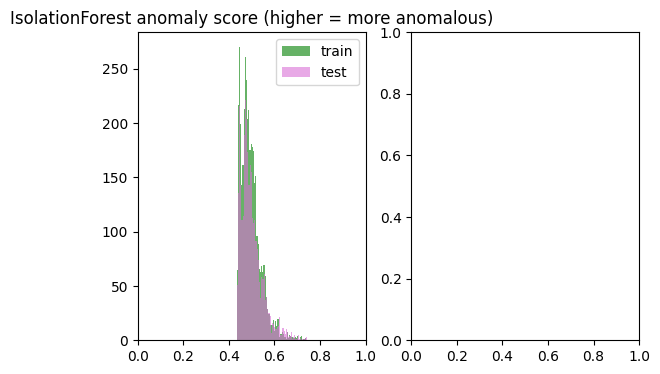

In [10]:
# Visualization 1: Score histograms
import matplotlib.pyplot as plt
plt.figure(figsize=(10,4))
plt.subplot(1,3,1)
plt.hist(scores_train, bins=60, alpha=0.6, label='train',color='green')
plt.hist(scores_test, bins=60, alpha=0.6, label='test',color='orchid')
plt.title('IsolationForest anomaly score (higher = more anomalous)')
plt.xlim(0,1)
plt.legend()
plt.subplot(1,3,2)
plt.hist(scores_test[y_test==True], bins=40, alpha=0.7, label='outliers')
plt.hist(scores_test[(~y_test.astype(bool))], bins=40, alpha=0.5, label='inliers')
plt.title('Test: outlier vs inlier score distributions')
plt.xlim(0,1)
plt.legend()
plt.subplot(1,3,3)
plt.hist(scores_train[y_train==True], bins=40, alpha=0.7, label='outliers')
plt.hist(scores_train[(~y_train.astype(bool))], bins=40, alpha=0.5, label='inliers')
plt.title('Train: outlier vs inlier score distributions')
plt.xlim(0,1)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / f'{STUDY_ID}_score_hists.png', dpi=200, bbox_inches='tight')
plt.show()

In [11]:
# Visualization 2: ROC / Precision-Recall
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
if len(y_test) > 0 and y_test.sum() > 0:
    fpr, tpr, _ = roc_curve(y_test, scores_test)
    prec, rec, _ = precision_recall_curve(y_test, scores_test)
    auc = roc_auc_score(y_test, scores_test)
    ap = average_precision_score(y_test, scores_test)
    import matplotlib.pyplot as plt
    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1)
    plt.plot(fpr, tpr, label=f'AUC={auc:.3f}')
    plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC curve'); plt.legend()
    plt.subplot(1,2,2)
    plt.plot(rec, prec, label=f'AP={ap:.3f}')
    plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-Recall'); plt.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{STUDY_ID}_roc_pr.png', dpi=200, bbox_inches='tight')
    plt.show()
else:
    print('No positive labels in test set; skipping ROC/PR')

ValueError: Found input variables with inconsistent numbers of samples: [8208, 3221]

In [48]:
traj_df['split-time']

0        2017-02-06 10:30:40.000
1        2017-02-06 10:30:40.000
2        2017-02-06 10:30:40.000
3        2017-02-06 10:30:40.000
4        2017-02-06 10:30:40.000
                  ...           
21392    2017-03-17 01:40:37.500
21393    2017-03-17 01:40:37.500
21394    2017-03-17 01:40:37.500
21395    2017-03-17 01:40:37.500
21396    2017-03-17 01:40:37.500
Name: split-time, Length: 21397, dtype: object

In [24]:
traj_df = pd.read_csv(study.trajectories_path)
pts = traj_df.set_index('point_id').loc[test_pids]
pts[pts[INDIVIDUAL_COL]==unique_individuals[0]]

,Unnamed: 0,event-id,visible,timestamp,location-long,location-lat,algorithm-marked-outlier,external-temperature,gps:hdop,gps:maximum-signal-strength,gps:satellite-count,height-above-msl,manually-marked-outlier,sensor-type,individual-taxon-canonical-name,tag-local-identifier,individual-local-identifier,study-name,split-time,set
point_id,,,,,,,,,,,,,,,,,,,,
3836,3836,5289854356,True,2017-07-31 14:20:38,141.042397,-33.200014,NaN,22.87,1.0,40.0,8,84.0,NaN,gps,Vulpes vulpes,151-3384,Flo,"Red Fox (Vulpes vulpes) - Scotia, NSW, Australia",2017-02-06 10:30:40.000,test
3837,3837,5289854357,True,2017-07-31 14:40:37,141.042356,-33.200047,NaN,23.87,0.9,40.0,9,82.0,NaN,gps,Vulpes vulpes,151-3384,Flo,"Red Fox (Vulpes vulpes) - Scotia, NSW, Australia",2017-02-06 10:30:40.000,test
3838,3838,5289854358,True,2017-07-31 15:00:37,141.042364,-33.200022,NaN,24.37,1.1,42.0,8,82.0,NaN,gps,Vulpes vulpes,151-3384,Flo,"Red Fox (Vulpes vulpes) - Scotia, NSW, Australia",2017-02-06 10:30:40.000,test
3839,3839,5289854359,True,2017-07-31 15:20:36,141.044833,-33.198764,NaN,18.18,1.1,46.0,7,87.0,NaN,gps,Vulpes vulpes,151-3384,Flo,"Red Fox (Vulpes vulpes) - Scotia, NSW, Australia",2017-02-06 10:30:40.000,test
3840,3840,5289854360,True,2017-07-31 15:40:37,141.050378,-33.198194,NaN,12.50,1.0,45.0,8,73.0,NaN,gps,Vulpes vulpes,151-3384,Flo,"Red Fox (Vulpes vulpes) - Scotia, NSW, Australia",2017-02-06 10:30:40.000,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4580,4580,5289855100,True,2017-08-14 23:00:36,141.043058,-33.181875,NaN,30.68,1.0,41.0,9,69.0,NaN,gps,Vulpes vulpes,151-3384,Flo,"Red Fox (Vulpes vulpes) - Scotia, NSW, Australia",2017-02-06 10:30:40.000,test
4581,4581,5289855101,True,2017-08-15 00:36:44,141.043158,-33.181689,NaN,35.56,1.1,43.0,9,61.0,NaN,gps,Vulpes vulpes,151-3384,Flo,"Red Fox (Vulpes vulpes) - Scotia, NSW, Australia",2017-02-06 10:30:40.000,test
4582,4582,5289855102,True,2017-08-15 02:12:44,141.043169,-33.180764,NaN,32.68,1.1,40.0,8,71.0,NaN,gps,Vulpes vulpes,151-3384,Flo,"Red Fox (Vulpes vulpes) - Scotia, NSW, Australia",2017-02-06 10:30:40.000,test


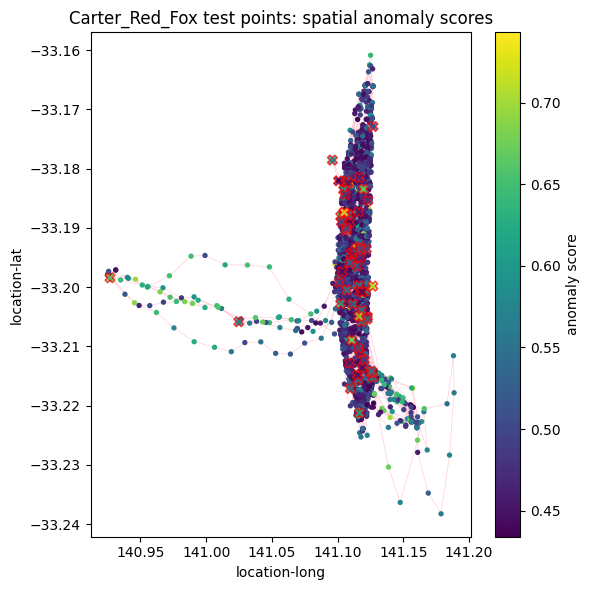

In [18]:

# Visualization 4: Spatial scatter of test points (requires LAT/LON cols)
try:
    from movebench.trajectories import LAT_COL, LON_COL
    traj_df = pd.read_csv(study.trajectories_path)
    pts = traj_df.set_index('point_id').loc[test_pids]
    pts = pts[pts[INDIVIDUAL_COL] ==unique_individuals[1]]  # filter to same individual as model
    plt.figure(figsize=(6,6))
    # Draw trajectory line connecting consecutive points in time
    pts_sorted = pts.sort_values('timestamp')
    plt.plot(pts_sorted[LON_COL], pts_sorted[LAT_COL], color='pink', linewidth=0.5, alpha=0.74, zorder=0)
    sc = plt.scatter(pts[LON_COL], pts[LAT_COL], c=scores_test, cmap='viridis', s=8)
    #set the colormap to be fixed across studies by using the global min/max of scores_test
    #sc.set_clim(0.25,0.8)    
    #add gt outliers as large X colored with the anomaly score
    gt_outliers = pts[y_test_filtered]
    plt.scatter(gt_outliers[LON_COL], gt_outliers[LAT_COL], c=scores_test[y_test_filtered],
                cmap='viridis', s=50, marker='X', edgecolor='red', label='GT outliers',alpha=0.75)
    plt.colorbar(sc, label='anomaly score')
    plt.title(f'{STUDY_ID} test points: spatial anomaly scores')
    plt.xlabel(LON_COL); plt.ylabel(LAT_COL)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{STUDY_ID}_spatial_scores_test_zoom.png', dpi=200, bbox_inches='tight')
    plt.show()
except Exception as e:
    print('Spatial plot failed (missing columns or mapping):', e)


In [ ]:

# Visualization 4: Spatial scatter of test points (requires LAT/LON cols)
try:
    from movebench.trajectories import LAT_COL, LON_COL
    traj_df = pd.read_csv(study.trajectories_path)
    pts = traj_df.set_index('point_id').loc[train_pids]
    plt.figure(figsize=(6,6))
    # Draw trajectory line connecting consecutive points in time
    pts_sorted = pts.sort_values('timestamp')
    plt.plot(pts_sorted[LON_COL], pts_sorted[LAT_COL], color='gray', linewidth=0.5, alpha=0.4, zorder=0)
    sc = plt.scatter(pts[LON_COL], pts[LAT_COL], c=scores_train, cmap='viridis', s=8)
    sc.set_clim(0.25,0.8)    
    #add gt outliers as large X colored with the anomaly score
    gt_outliers = pts[y_train]
    plt.scatter(gt_outliers[LON_COL], gt_outliers[LAT_COL], c=scores_train[y_train],
                cmap='viridis', s=50, marker='X', edgecolor='red', label='GT outliers',alpha=0.75)
    plt.colorbar(sc, label='anomaly score')
    plt.title(f'{STUDY_ID} test points: spatial anomaly scores')
    plt.xlabel(LON_COL); plt.ylabel(LAT_COL)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{STUDY_ID}_spatial_scores_train.png', dpi=200, bbox_inches='tight')
    plt.show()
except Exception as e:
    print('Spatial plot failed (missing columns or mapping):', e)


In [80]:
# Visualization 6: Scores per individual (boxplot)
try:
    from movebench.trajectories import INDIVIDUAL_COL
    traj_df = pd.read_csv(study.trajectories_path)
    df_scores = pd.DataFrame({'point_id': test_pids, 'score': scores_test})
    df_scores = df_scores.merge(traj_df[[ 'point_id', INDIVIDUAL_COL ]], on='point_id', how='left')
    import seaborn as sns
    plt.figure(figsize=(10,4))
    sns.boxplot(x=INDIVIDUAL_COL, y='score', data=df_scores)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{STUDY_ID}_by_individual.png', dpi=200, bbox_inches='tight')
    plt.show()
except Exception as e:
    print('Per-individual plot failed:', e)

Per-individual plot failed: No module named 'seaborn'


In [2]:
import os
# consolidate results:
all_dfs = []
for csv in os.listdir(RESULTS_DIR):
    if csv.endswith('.csv'):
        df = pd.read_csv(os.path.join(RESULTS_DIR, csv))
        df['proportion_pos_test'] = df['n_test_pos'] / df['n_test']
        all_dfs.append(df)
all_results_df = pd.concat(all_dfs, ignore_index=True)
all_results_df.to_csv(RESULTS_DIR / 'isoforest_all_results.csv', index=False)
all_results_df

,study,n_train,n_test,n_test_pos,roc_auc_test,roc_auc_train,average_precision_test,average_precision_train,proportion_pos_test
0,atlas_bats,16074,12490,4519,0.685427,0.767112,0.584402,0.476143,0.361809
1,Hill_upland_sandpiper,1650,1331,8,0.809240,0.799462,0.064850,0.101143,0.006011
2,Carter_Red_Fox,12989,8208,98,0.528269,0.570266,0.021519,0.027436,0.011940
3,Bildstein_turkey_vulture,61780,53974,7,0.713915,0.923623,0.000326,0.000598,0.000130
4,"cross2016_Kruger_African_Buffalo,_GPS_tracking...",13112,11222,1,0.518759,0.555700,0.000185,0.001101,0.000089
5,Byholm_European_honey-buzzard,3215,4410,26,0.596338,0.555072,0.007625,0.000699,0.005896
6,Roshier_feral_cat__european_red_fox,22737,11258,48,0.544334,0.435358,0.006138,0.002728,0.004264
